In [100]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [101]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [102]:
mov_ind = 4

In [103]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=mov_ind)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind

current stimulus is opticflow


# Train/test validation - epochs

Test optimum seems to be at 5-10

In [121]:
N_training_repeats = 1
iterations_array = np.array([1, 5, 10, 15, 20, 30])
cg_params = {
    "order": 1,
    "output_dim": 20
}

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}

# opt_params = {"track_quantities": False, "quiet": True, "iterations": 50}
opt_params = {"track_quantities": False, "quiet": True}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 5
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

## Prepare data

In [122]:
D.reset()
D.trim(20)
V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [123]:
experiment_dims = (len(iterations_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for n, iterations in tqdm(enumerate(iterations_array)):
    for training_repeat in range(N_training_repeats):
        cur_inds = (n, training_repeat)
        coarse_grainer = mds.PolynomialLayer(**cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[cur_inds] = current_train_points
        test_points[cur_inds] = current_test_points

        # Train current
        opt_params["iterations"] = iterations
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[cur_inds] = mi_train["mi"]
        mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[cur_inds] = mi_test["mi"]
        mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

        coarse_grainer_array[cur_inds] = coarse_grainer
        critic_function_array[cur_inds] = critic_function

6it [00:39,  6.55s/it]


In [124]:
mi_averages_test / np.log(2), mi_stdevs_test / np.log(2)

(array([[1.31563351],
        [1.55768045],
        [1.6122369 ],
        [1.56933   ],
        [1.56871503],
        [1.49231391]]),
 array([[0.00878961],
        [0.01022798],
        [0.01136743],
        [0.01123765],
        [0.01157621],
        [0.01283744]]))

In [125]:
mi_averages_train / np.log(2), mi_stdevs_train / np.log(2)

(array([[1.40312055],
        [1.7460438 ],
        [1.90196469],
        [1.97762791],
        [2.02485571],
        [2.09170168]]),
 array([[0.00913795],
        [0.01084759],
        [0.0115542 ],
        [0.01136394],
        [0.01306322],
        [0.01177776]]))

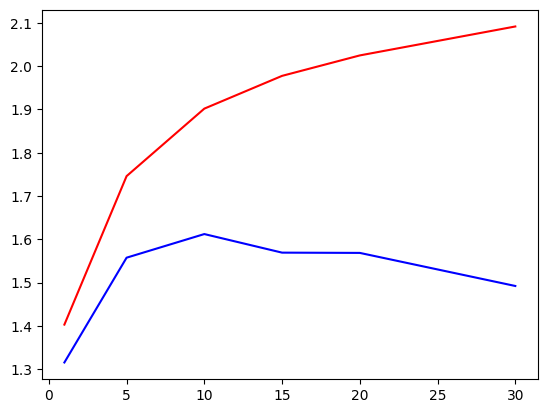

In [126]:
plt.plot(iterations_array, mi_averages_test/np.log(2), color='blue')
plt.plot(iterations_array, mi_averages_train/np.log(2), color='red')

# Train/test validation - hidden and embed dim

- Embed dim is sloppy
- hidden dim optimum around 40-80



In [136]:
N_training_repeats = 1
embed_dim_array = np.array([20, 30, 40, 50])
hidden_dim_array = np.array([10, 20, 40, 80, 160, 320, 640])
cg_params = {
    "order": 1,
    "output_dim": D.N
}

critic_params = {
    # "hidden_dim": 100,
    # "embed_dim": 100,
    "layers": 3,
    "activation": "tanh",
}

opt_params = {"track_quantities": False, "quiet": True, "iterations": 5}
# opt_params = {"track_quantities": False, "quiet": True}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 3
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

## Prepare data

In [137]:
D.reset()
D.trim(20)
V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [138]:
experiment_dims = (len(embed_dim_array), len(hidden_dim_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for i, embed_dim in tqdm(enumerate(embed_dim_array)):
    for j, hidden_dim in enumerate(hidden_dim_array):
        for training_repeat in range(N_training_repeats):
            cur_inds = (i, j, training_repeat)
            coarse_grainer = mds.PolynomialLayer(**cg_params)
            critic_params["embed_dim"] = embed_dim
            critic_params["hidden_dim"] = hidden_dim
            critic_function = mds.SeparableCritic(**critic_params)

            # make training and test subsets
            V.reset()
            E.reset()
            current_train_points, current_test_points = tools.generate_train_test_indices(
                V.P, train_fraction
            )
            V.subset_points(current_train_points)
            E.subset_points(current_train_points)
            train_points[cur_inds] = current_train_points
            test_points[cur_inds] = current_test_points

            # Train current
            als.IB(
                X=V.X,
                Y=E.X,
                coarse_grainer=coarse_grainer,
                critic_function=critic_function,
                **opt_params
            )

            # Measure InfoNCE for train
            T_train = coarse_grainer(V.X.T).numpy().T
            mi_train = als.MI_NCE(
                X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_train[cur_inds] = mi_train["mi"]
            mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

            # Measure InfoNCE for test
            V.reset()
            E.reset()
            V.subset_points(current_test_points)
            E.subset_points(current_test_points)
            T_test = coarse_grainer(V.X.T).numpy().T
            mi_test = als.MI_NCE(
                X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_test[cur_inds] = mi_test["mi"]
            mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

            coarse_grainer_array[cur_inds] = coarse_grainer
            critic_function_array[cur_inds] = critic_function

4it [02:53, 43.27s/it]


In [139]:
mean_test = np.mean(mi_averages_test, axis=-1)
mean_train = np.mean(mi_averages_train, axis=-1)

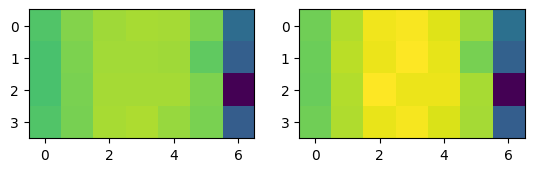

In [140]:
vmin = np.min(mean_test)
vmax = np.max(mean_train)
# vmin = 0
# vmax = 6

fig, ax = plt.subplots(ncols=2)
ax[0].imshow(mean_test, vmin=vmin, vmax=vmax)
ax[1].imshow(mean_train, vmin=vmin, vmax=vmax)

In [141]:
ed_test = np.mean(mean_test, axis=0)
ed_train = np.mean(mean_train, axis=0)

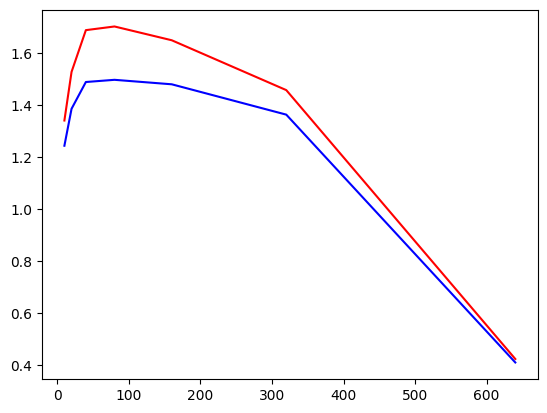

In [142]:
plt.plot(hidden_dim_array, ed_test/np.log(2), color='blue')
plt.plot(hidden_dim_array, ed_train/np.log(2), color='red')
# plt.gca().set_ylim(0, 8)

In [143]:
ed_test / np.log(2), ed_train / np.log(2)

(array([1.24354411, 1.38571315, 1.48876279, 1.49721403, 1.47997383,
        1.36323249, 0.40959035]),
 array([1.34060613, 1.52774181, 1.68834644, 1.7024477 , 1.64940753,
        1.45760713, 0.42300503]))